# 04b · SHAP Explanations and Subgroup Fairness
**SIADS 699 · Group 20 · Guardians of the Statinverse**

This notebook explains the selected model's predictions (who is at risk, and why) and checks whether the model works equally well across patient groups.

| Section | Epic | Task | Deliverable | Owner | Due |
|---|---|---|---|---|---|
| 3–5 Per-patient drivers | KAN-8 | KAN-27 | `patient_drivers.csv` (KAN-90) | Rachel | Nov 23 |
| 6 Global importance | KAN-8 | KAN-28 | `global_importance.csv` (KAN-91) | Rachel | Nov 23 |
| 7 Stability and literature check | KAN-8 | KAN-29 | Notes in this notebook and the report | Rachel | Nov 23 |
| 8 Subgroup fairness | KAN-9 | KAN-30 | `subgroup_metrics.csv` (KAN-92) | Rachel | Nov 23 |

*These Jira notes are for team coordination and will be removed from the final notebook we submit.*

> **Status:** runs on the pre-freeze model artifacts in `models/`. Rerun top to bottom after the Nov 16 model freeze; nothing else needs to change.

**Inputs:** `models/*.joblib` from notebook 03, `data/processed/baseline_person_dataset.csv` (for `DUPERSID`), and `data/raw/h252dta.zip` (family income, used only for the fairness groups).

**Data rule:** `patient_drivers.csv` has one row per person with `DUPERSID`, so it is written to the git-ignored `data/processed/` folder and shared through the team drive, never committed. Only aggregate tables and charts go to `results/`. This notebook prints no patient-level rows.

## 1. Setup

In [1]:
%matplotlib inline
import tempfile
import warnings
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyreadstat
import xgboost as xgb
from scipy.stats import rankdata, spearmanr
from sklearn.base import clone
from sklearn.metrics import brier_score_loss, roc_auc_score

In [2]:
# ---------- Paths ----------
ROOT = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "src" / "download_meps.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not find the repository root.")

MODEL_DIR     = ROOT / "models"
PROCESSED_DIR = ROOT / "data" / "processed"        # git-ignored: patient-level files live here
RAW_DIR       = ROOT / "data" / "raw"
RESULTS_DIR   = ROOT / "results"                   # committed: aggregate tables and charts only
RESULTS_DIR.mkdir(exist_ok=True)

PATIENT_DRIVERS_FILE = PROCESSED_DIR / "patient_drivers.csv"   # KAN-90 (never commit)
GLOBAL_FILE          = RESULTS_DIR / "global_importance.csv"   # KAN-91
SUBGROUP_FILE        = RESULTS_DIR / "subgroup_metrics.csv"    # KAN-92
DICTIONARY_FILE      = RESULTS_DIR / "driver_dictionary.csv"   # feature → plain label → RAG driver
STABILITY_FILE       = RESULTS_DIR / "shap_stability.csv"

# ---------- Model ----------
FINAL_MODEL = "XGBoost - Full Features"   # selected in notebook 04, Section 5

# ---------- Risk tiers (PLACEHOLDER until the team agrees) ----------
# High: at or above 0.10, the operating threshold notebook 04 uses for its subgroup section
#       (about the top fifth of patients, 1.25x the 8% base rate).
# Low:  below 0.05, well under the base rate.
HIGH_RISK = 0.10
LOW_RISK  = 0.05

# ---------- Drivers and fairness ----------
TOP_N                = 3     # drivers per patient
MIN_EVENTS_FOR_AUROC = 10    # fewer discontinued patients than this → AUROC left blank (too unstable)
N_BOOT               = 1000  # bootstrap resamples for confidence intervals
N_STABILITY_REFITS   = 10    # bootstrap refits for the KAN-29 stability check
SEED                 = 42

# ---------- Chart style (one series per chart, so one hue) ----------
SERIES = "#2a78d6"
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": True, "axes.grid.axis": "x",
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "axes.spines.left": False, "font.size": 10,
})
print("Repository:", ROOT)

Repository: /Users/rachel/statin-discontinuation


## 2. Load the Model and Score Every Patient

Every patient gets an **out-of-sample** risk score, i.e. from a model that did not see them:
- **Training set (1,071):** the out-of-fold predictions saved by notebook 03.
- **Test set (268):** the final model's predictions.

Using all 1,339 patients (instead of only the 268 test patients) is what makes the subgroup estimates in Section 8 usable: the test set alone has only 21 discontinued patients.

The model artifacts were saved with scikit-learn 1.3.2. Load them with that version (Deepnote's default environment has it).

In [3]:
fitted_models       = joblib.load(MODEL_DIR / "candidate_models.joblib")
feature_definitions = joblib.load(MODEL_DIR / "feature_definitions.joblib")
data_splits         = joblib.load(MODEL_DIR / "data_splits.joblib")
oof_probabilities   = joblib.load(MODEL_DIR / "oof_probabilities.joblib")

model    = fitted_models[FINAL_MODEL]
FEATURES = feature_definitions["full_features"]
X_train, X_test = data_splits["X_train"], data_splits["X_test"]
y_train, y_test = data_splits["y_train"], data_splits["y_test"]

print(f"Model: {FINAL_MODEL} with {len(FEATURES)} features")
print(f"Train: {len(X_train):,} people, {int(y_train.sum())} discontinued | "
      f"Test: {len(X_test):,} people, {int(y_test.sum())} discontinued")

Model: XGBoost - Full Features with 26 features
Train: 1,071 people, 86 discontinued | Test: 268 people, 21 discontinued


In [4]:
# Rebuild notebook 03's modeling table to attach DUPERSID (the splits keep only the row index).
baseline = pd.read_csv(PROCESSED_DIR / "baseline_person_dataset.csv", dtype={"DUPERSID": "string"})
baseline["fill_change"] = (baseline["statin_purchase_count_round_2"]
                           - baseline["statin_purchase_count_round_1"])
baseline["single_fill"] = ((baseline["statin_purchase_count_round_1"]
                            + baseline["statin_purchase_count_round_2"]) == 1).astype(int)
for col in ["EDUCYR_round_1", "HIDEG_round_1", "RTHLTH_round_1", "MNHLTH_round_1"]:
    baseline[col] = baseline[col].replace({-7: np.nan, -8: np.nan})

X_all = pd.concat([X_train, X_test])[FEATURES]
y_all = pd.concat([y_train, y_test])

# The row index must point at the same person in both tables.
rebuilt = baseline.loc[X_all.index, FEATURES]
same = (rebuilt.values == X_all.values) | (rebuilt.isna().values & X_all.isna().values)
assert same.all(), "Model features do not match the rebuilt baseline rows"
assert (baseline.loc[X_all.index, "discontinued"].values == y_all.values).all()
assert X_all.index.is_unique and len(X_all) == len(baseline)

test_probabilities = model.predict_proba(X_test[FEATURES])[:, 1]

scored = pd.DataFrame({
    "DUPERSID": baseline.loc[X_all.index, "DUPERSID"].values,
    "discontinued": y_all.values,
    "risk_score": np.r_[oof_probabilities, test_probabilities],
    "prediction_source": ["out_of_fold"] * len(X_train) + ["test"] * len(X_test),
}, index=X_all.index)
scored["risk_tier"] = pd.cut(scored["risk_score"], [-np.inf, LOW_RISK, HIGH_RISK, np.inf],
                             right=False, labels=["Low", "Medium", "High"])

print("Every row matched to its DUPERSID.")
print(f"Out-of-sample AUROC, all {len(scored):,} patients: "
      f"{roc_auc_score(scored['discontinued'], scored['risk_score']):.3f}")
tiers = scored.groupby("risk_tier", observed=True).agg(
    patients=("risk_score", "size"), discontinued=("discontinued", "sum"),
    actual_rate=("discontinued", "mean"), predicted_rate=("risk_score", "mean"))
display(tiers.round(3))

Every row matched to its DUPERSID.
Out-of-sample AUROC, all 1,339 patients: 0.669


,patients,discontinued,actual_rate,predicted_rate
risk_tier,,,,
Low,531,23,0.043,0.036
Medium,509,39,0.077,0.069
High,299,45,0.151,0.163


## 3. Driver Dictionary: Feature → Plain Language → RAG Driver

Downstream users need three things for each feature:
- a **plain-language label** for the app (KAN-27 asks for plain-language drivers);
- the **RAG driver** it maps to, so the lookup table (KAN-69) can find guidance. The RAG notebook uses its own short names (`statin_oop_cost`, `med_count`, ...), so this table is the bridge;
- whether it is **actionable**. Age, sex, race/ethnicity, and education are not something a care coordinator can change, so they get no RAG search.

The `rag_driver` column is a **proposal** to confirm later. Saved to `results/driver_dictionary.csv`.

In [5]:
YES_NO = {1: "Yes", 2: "No"}
HEALTH = {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor"}
CODE_LABELS = {
    "SEX_round_1":     {1: "Male", 2: "Female"},
    "RACETHX_round_1": {1: "Hispanic", 2: "Non-Hispanic White", 3: "Non-Hispanic Black",
                        4: "Non-Hispanic Asian", 5: "Non-Hispanic other or multiple races"},
    "HISPANX_round_1": {1: "Hispanic", 2: "Not Hispanic"},
    "HIDEG_round_1":   {1: "No degree", 2: "GED", 3: "High school diploma", 4: "Bachelor's degree",
                        5: "Master's degree", 6: "Doctorate", 7: "Other degree", 8: "Under 16"},
    "RTHLTH_round_1": HEALTH, "MNHLTH_round_1": HEALTH,
    "INS_round_1": YES_NO, "MCARE_round_1": YES_NO, "MCAID_round_1": YES_NO,
    "PRIVAT_round_1": YES_NO, "PMEDIN_round_1": YES_NO,
    "single_fill": {0: "No", 1: "Yes"},
}

# feature: (plain label, value kind, proposed RAG driver or None, actionable)
DICTIONARY = {
    "statin_purchase_count_round_1":  ("Statin fills in round 1", "count", "fill_change", True),
    "statin_purchase_count_round_2":  ("Statin fills in round 2", "count", "fill_change", True),
    "statin_rx_cost_round_1":         ("Statin out-of-pocket cost, round 1", "dollars", "statin_oop_cost", True),
    "statin_rx_cost_round_2":         ("Statin out-of-pocket cost, round 2", "dollars", "statin_oop_cost", True),
    "statin_rx_cost_baseline_total":  ("Statin out-of-pocket cost, rounds 1-2", "dollars", "statin_oop_cost", True),
    "fill_change":                    ("Change in statin fills, round 1 to 2", "signed", "fill_change", True),
    "single_fill":                    ("Only one statin fill in rounds 1-2", "code", "single_fill", True),
    "AGE_round_1":                    ("Age", "years", None, False),
    "SEX_round_1":                    ("Sex", "code", None, False),
    "RACETHX_round_1":                ("Race and ethnicity", "code", None, False),
    "HISPANX_round_1":                ("Hispanic ethnicity", "code", None, False),
    "EDUCYR_round_1":                 ("Years of education", "years", None, False),
    "HIDEG_round_1":                  ("Highest degree", "code", None, False),
    "RTHLTH_round_1":                 ("Self-rated physical health", "code", None, False),
    "MNHLTH_round_1":                 ("Self-rated mental health", "code", "cond_depression", True),
    "INS_round_1":                    ("Has health insurance", "code", "insurance_type", True),
    "MCARE_round_1":                  ("Has Medicare", "code", "insurance_type", True),
    "MCAID_round_1":                  ("Has Medicaid", "code", "insurance_type", True),
    "PRIVAT_round_1":                 ("Has private insurance", "code", "insurance_type", True),
    "PMEDIN_round_1":                 ("Has private prescription drug coverage", "code", "insurance_type", True),
    "rx_purchase_count_round_1":      ("Prescription fills (all drugs), round 1", "count", "med_count", True),
    "rx_purchase_count_round_2":      ("Prescription fills (all drugs), round 2", "count", "med_count", True),
    "distinct_drug_count_round_1":    ("Different medications, round 1", "count", "med_count", True),
    "distinct_drug_count_round_2":    ("Different medications, round 2", "count", "med_count", True),
    "active_condition_count_round_1": ("Active medical conditions, round 1", "count", "cond_count", True),
    "active_condition_count_round_2": ("Active medical conditions, round 2", "count", "cond_count", True),
}
assert set(DICTIONARY) == set(FEATURES), set(FEATURES) ^ set(DICTIONARY)


def format_value(feature, value):
    """Readable text for one patient's feature value."""
    if pd.isna(value):
        return "Missing"
    kind = DICTIONARY[feature][1]
    if kind == "code":
        return CODE_LABELS[feature].get(int(value), str(value))
    if kind == "dollars":
        return f"${value:,.2f}"
    if kind == "signed":
        return f"{int(value):+d}"
    return f"{int(value)}"


driver_dictionary = pd.DataFrame(
    [(f, *DICTIONARY[f]) for f in FEATURES],
    columns=["feature", "label", "value_kind", "rag_driver", "actionable"])
driver_dictionary.to_csv(DICTIONARY_FILE, index=False)
print(f"Saved {DICTIONARY_FILE.relative_to(ROOT)}")
display(driver_dictionary)

Saved results/driver_dictionary.csv


,feature,label,value_kind,rag_driver,actionable
0,statin_purchase_count_round_1,Statin fills in round 1,count,fill_change,True
1,statin_purchase_count_round_2,Statin fills in round 2,count,fill_change,True
2,statin_rx_cost_round_1,"Statin out-of-pocket cost, round 1",dollars,statin_oop_cost,True
3,statin_rx_cost_round_2,"Statin out-of-pocket cost, round 2",dollars,statin_oop_cost,True
4,statin_rx_cost_baseline_total,"Statin out-of-pocket cost, rounds 1-2",dollars,statin_oop_cost,True
5,fill_change,"Change in statin fills, round 1 to 2",signed,fill_change,True
6,single_fill,Only one statin fill in rounds 1-2,code,single_fill,True
7,AGE_round_1,Age,years,None,False
8,SEX_round_1,Sex,code,None,False
9,RACETHX_round_1,Race and ethnicity,code,None,False


## 4. SHAP Values

XGBoost's built-in TreeSHAP (`pred_contribs=True`, the same exact algorithm as `shap.TreeExplainer`) gives SHAP values in **log-odds** units: positive pushes risk up, negative pushes it down. Using XGBoost directly avoids a version clash between the `shap` package and XGBoost 3.

Two details:
- The model one-hot encodes categorical features (68 model columns from 26 features). We **sum the SHAP values of each feature's columns** so every driver is an original feature name that matches the dictionary.
- SHAP explains the **final** model (trained on the training set). For test patients that is exactly the model behind their risk score. For training patients the score is out-of-fold, so their SHAP values describe the final model, which saw them. Refitting the fold models does not reproduce notebook 03's out-of-fold predictions exactly across machines (differences up to 0.03), so we keep the team's saved scores and note this here.

SHAP shows what the model relies on. It does **not** show what causes discontinuation, and the app and report wording should say "linked to higher predicted risk", not "causes".

In [6]:
preprocessor = model.named_steps["preprocessor"]
classifier   = model.named_steps["classifier"]

X_model = preprocessor.transform(X_all[FEATURES])
X_model = X_model.toarray() if hasattr(X_model, "toarray") else np.asarray(X_model)
model_columns = preprocessor.get_feature_names_out()

def tree_shap(xgb_classifier, X):
    """Exact TreeSHAP from XGBoost: (SHAP matrix, base value) in log-odds."""
    contributions = xgb_classifier.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)
    contributions = contributions.astype(np.float64)
    return contributions[:, :-1], float(contributions[0, -1])


shap_model, base_value = tree_shap(classifier, X_model)

# Additivity check: base value + SHAP values = the model's log-odds for every patient.
final_probability = model.predict_proba(X_all[FEATURES])[:, 1]
log_odds = np.log(final_probability / (1 - final_probability))
assert np.allclose(base_value + shap_model.sum(axis=1), log_odds, atol=1e-4)


def original_feature(column):
    """'cat__SEX_round_1_2.0' → 'SEX_round_1'; 'num__AGE_round_1' → 'AGE_round_1'."""
    name = column.split("__", 1)[1]
    matches = [f for f in FEATURES if name == f or name.startswith(f + "_")]
    return max(matches, key=len)


column_to_feature = pd.Series([original_feature(c) for c in model_columns], index=model_columns)
shap_values = (pd.DataFrame(shap_model, columns=model_columns, index=X_all.index)
               .T.groupby(column_to_feature).sum().T[FEATURES])

assert np.allclose(shap_values.sum(axis=1), shap_model.sum(axis=1))
print(f"SHAP values: {shap_values.shape[0]:,} patients x {shap_values.shape[1]} features")
print(f"Base value (average log-odds): {base_value:.3f}  →  probability {1 / (1 + np.exp(-base_value)):.3f}")

SHAP values: 1,339 patients x 26 features
Base value (average log-odds): -2.466  →  probability 0.078


## 5. Per-Patient Drivers (KAN-27 → `patient_drivers.csv`, KAN-90)

**Rule:** a patient's drivers are their features with **SHAP > 0**, largest first, up to 3. Ranking by absolute value would list risk-*lowering* features as reasons for risk. A patient with fewer than 3 positive features gets blank driver columns.

**Columns:** `DUPERSID`, `risk_score`, `risk_tier`, then for each driver `driver_k` (feature name), `driver_k_value` (readable value), `driver_k_shap`. Two additions beyond KAN-90: `driver_k_label` (plain language for the app) and `prediction_source` (`out_of_fold` or `test`).

`prior_heart_or_stroke` (in the RAG template) is not in the modeling data yet, so it is not included.

In [7]:
rows = []
for idx in scored.index:
    positive = shap_values.loc[idx]
    positive = positive[positive > 0].nlargest(TOP_N)
    row = {
        "DUPERSID": scored.at[idx, "DUPERSID"],
        "risk_score": round(float(scored.at[idx, "risk_score"]), 4),
        "risk_tier": scored.at[idx, "risk_tier"],
        "prediction_source": scored.at[idx, "prediction_source"],
    }
    for k in range(1, TOP_N + 1):
        if k <= len(positive):
            feature = positive.index[k - 1]
            row[f"driver_{k}"] = feature
            row[f"driver_{k}_label"] = DICTIONARY[feature][0]
            row[f"driver_{k}_value"] = format_value(feature, X_all.at[idx, feature])
            row[f"driver_{k}_shap"] = round(float(positive.iloc[k - 1]), 4)
        else:
            row.update({f"driver_{k}": None, f"driver_{k}_label": None,
                        f"driver_{k}_value": None, f"driver_{k}_shap": np.nan})
    rows.append(row)

patient_drivers = pd.DataFrame(rows).sort_values("risk_score", ascending=False)
patient_drivers.to_csv(PATIENT_DRIVERS_FILE, index=False)
print(f"Saved {len(patient_drivers):,} rows to {PATIENT_DRIVERS_FILE.relative_to(ROOT)} "
      "(git-ignored; share through the team drive)")

# Aggregate checks only: no patient rows are printed.
n_drivers = patient_drivers[[f"driver_{k}" for k in range(1, TOP_N + 1)]].notna().sum(axis=1)
print("\nPatients by number of risk-raising drivers:")
display(n_drivers.value_counts().sort_index().rename("patients").to_frame())

Saved 1,339 rows to data/processed/patient_drivers.csv (git-ignored; share through the team drive)

Patients by number of risk-raising drivers:


,patients
2,2
3,1337


In [8]:
# Which drivers appear most often in the top 3, by tier?
long = (patient_drivers
        .melt(id_vars="risk_tier", value_vars=[f"driver_{k}" for k in range(1, TOP_N + 1)],
              value_name="feature")
        .dropna(subset=["feature"]))
long["label"] = long["feature"].map(lambda f: DICTIONARY[f][0])
tier_size = patient_drivers["risk_tier"].value_counts()
driver_share = (long.groupby(["risk_tier", "label"], observed=True).size()
                .div(tier_size, level="risk_tier").rename("share_of_patients").reset_index())
for tier in ["High", "Medium", "Low"]:
    print(f"\n{tier} risk ({tier_size[tier]} patients): most common top-3 drivers")
    display(driver_share[driver_share["risk_tier"] == tier]
            .nlargest(5, "share_of_patients")[["label", "share_of_patients"]].round(3))

# Every driver must map to a dictionary row; actionable ones also need a RAG driver.
used = set(long["feature"])
no_rag = sorted(f for f in used if DICTIONARY[f][3] and DICTIONARY[f][2] is None)
assert used <= set(DICTIONARY) and not no_rag, no_rag
print("\nEvery driver used has a dictionary entry; every actionable driver has a proposed RAG driver.")


High risk (299 patients): most common top-3 drivers


,label,share_of_patients
3,"Different medications, round 2",0.562
9,Race and ethnicity,0.472
7,"Prescription fills (all drugs), round 1",0.465
6,Only one statin fill in rounds 1-2,0.441
10,Self-rated mental health,0.381



Medium risk (509 patients): most common top-3 drivers


,label,share_of_patients
53,Race and ethnicity,0.405
54,Self-rated mental health,0.354
60,"Statin out-of-pocket cost, rounds 1-2",0.279
51,"Prescription fills (all drugs), round 1",0.271
46,Has Medicare,0.263



Low risk (531 patients): most common top-3 drivers


,label,share_of_patients
24,Has private prescription drug coverage,0.311
15,"Active medical conditions, round 1",0.303
33,Sex,0.267
18,"Change in statin fills, round 1 to 2",0.250
38,"Statin out-of-pocket cost, rounds 1-2",0.232



Every driver used has a dictionary entry; every actionable driver has a proposed RAG driver.


## 6. Global Importance (KAN-28 → `global_importance.csv`, KAN-91)

Importance = **mean |SHAP|** across patients, ranked within each tier. The ticket asks for the columns `feature`, `mean_abs_shap`, `rank`; we add:
- `tier`: `All`, `High`, `Medium`, `Low` (the ticket also asks for top drivers per tier);
- `label`: plain-language name for the app chart;
- `direction`: for numeric and ordered features, how the feature's value relates to its SHAP value (Spearman correlation). `higher → more risk` means larger values push risk up. Unordered categories (sex, race/ethnicity, insurance yes/no) say `by category`.

In [9]:
UNORDERED = {"SEX_round_1", "RACETHX_round_1", "HISPANX_round_1", "HIDEG_round_1",
             "INS_round_1", "MCARE_round_1", "MCAID_round_1", "PRIVAT_round_1", "PMEDIN_round_1"}


def direction(feature, idx):
    if feature in UNORDERED:
        return "by category"
    values, effects = X_all.loc[idx, feature], shap_values.loc[idx, feature]
    keep = values.notna()
    if values[keep].nunique() < 2:
        return "no variation"
    rho = spearmanr(values[keep], effects[keep]).statistic
    if abs(rho) < 0.1:
        return "mixed"
    return "higher → more risk" if rho > 0 else "higher → less risk"


tables = []
for tier in ["All", "High", "Medium", "Low"]:
    idx = scored.index if tier == "All" else scored.index[scored["risk_tier"] == tier]
    t = (shap_values.loc[idx].abs().mean().rename("mean_abs_shap").reset_index()
         .rename(columns={"index": "feature"}))
    t["rank"] = t["mean_abs_shap"].rank(ascending=False, method="first").astype(int)
    t["tier"] = tier
    t["n_patients"] = len(idx)
    t["label"] = t["feature"].map(lambda f: DICTIONARY[f][0])
    t["direction"] = [direction(f, idx) for f in t["feature"]]
    tables.append(t.sort_values("rank"))

global_importance = pd.concat(tables, ignore_index=True)[
    ["tier", "rank", "feature", "label", "mean_abs_shap", "direction", "n_patients"]]
global_importance["mean_abs_shap"] = global_importance["mean_abs_shap"].round(5)
global_importance.to_csv(GLOBAL_FILE, index=False)
print(f"Saved {GLOBAL_FILE.relative_to(ROOT)}")
display(global_importance[global_importance["tier"] == "All"].head(15))

Saved results/global_importance.csv


,tier,rank,feature,label,mean_abs_shap,direction,n_patients
0,All,1,RACETHX_round_1,Race and ethnicity,0.21267,by category,1339
1,All,2,MNHLTH_round_1,Self-rated mental health,0.18101,higher → more risk,1339
2,All,3,distinct_drug_count_round_2,"Different medications, round 2",0.17432,higher → less risk,1339
3,All,4,single_fill,Only one statin fill in rounds 1-2,0.13378,higher → more risk,1339
4,All,5,rx_purchase_count_round_1,"Prescription fills (all drugs), round 1",0.13103,higher → less risk,1339
5,All,6,statin_rx_cost_baseline_total,"Statin out-of-pocket cost, rounds 1-2",0.12766,higher → more risk,1339
6,All,7,MCARE_round_1,Has Medicare,0.08288,by category,1339
7,All,8,active_condition_count_round_1,"Active medical conditions, round 1",0.07609,higher → less risk,1339
8,All,9,active_condition_count_round_2,"Active medical conditions, round 2",0.06321,mixed,1339
9,All,10,AGE_round_1,Age,0.05653,higher → less risk,1339


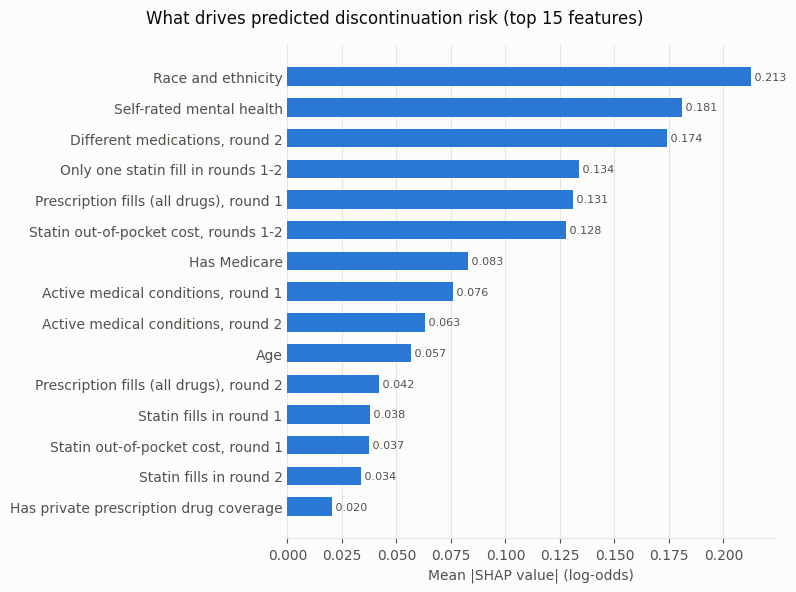

In [10]:
top = global_importance[global_importance["tier"] == "All"].head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["label"], top["mean_abs_shap"], color=SERIES, height=0.6)
for y, v in enumerate(top["mean_abs_shap"]):
    ax.text(v, y, f" {v:.3f}", va="center", fontsize=8, color=INK_2)
ax.set_xlabel("Mean |SHAP value| (log-odds)")
fig.suptitle("What drives predicted discontinuation risk (top 15 features)", fontsize=12)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "global_importance.png", dpi=200)
plt.show()

In [11]:
# Top 5 per tier, side by side
per_tier = (global_importance[global_importance["rank"] <= 5]
            .pivot(index="rank", columns="tier", values="label")[["All", "High", "Medium", "Low"]])
display(per_tier)

tier,All,High,Medium,Low
rank,,,,
1,Race and ethnicity,"Different medications, round 2",Race and ethnicity,Race and ethnicity
2,Self-rated mental health,Race and ethnicity,Self-rated mental health,Self-rated mental health
3,"Different medications, round 2",Only one statin fill in rounds 1-2,"Different medications, round 2","Different medications, round 2"
4,Only one statin fill in rounds 1-2,"Prescription fills (all drugs), round 1","Statin out-of-pocket cost, rounds 1-2","Statin out-of-pocket cost, rounds 1-2"
5,"Prescription fills (all drugs), round 1",Self-rated mental health,Only one statin fill in rounds 1-2,Only one statin fill in rounds 1-2


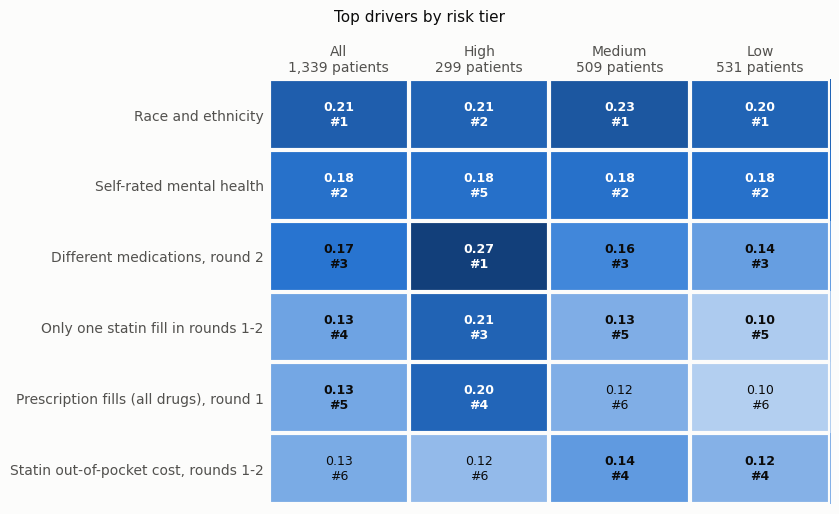

In [12]:
# Top drivers by tier as a heatmap: colour = mean |SHAP| (shared scale), label = value and rank in that tier.
from matplotlib.colors import LinearSegmentedColormap

TIERS = ["All", "High", "Medium", "Low"]
in_top5 = global_importance.loc[global_importance["rank"] <= 5, "feature"].unique()
row_order = (global_importance[(global_importance["tier"] == "All") & global_importance["feature"].isin(in_top5)]
             .sort_values("rank"))
value = global_importance.pivot(index="feature", columns="tier", values="mean_abs_shap").loc[row_order["feature"], TIERS]
rank  = global_importance.pivot(index="feature", columns="tier", values="rank").loc[row_order["feature"], TIERS]

low, high = value.values.min(), value.values.max()
cmap = LinearSegmentedColormap.from_list("one_hue", ["#eef4fc", SERIES, "#123f7a"])
fig, ax = plt.subplots(figsize=(8.5, 0.6 * len(value) + 1.6))
ax.imshow(value.values, cmap=cmap, vmin=low - 0.03, vmax=high, aspect="auto")
for i in range(value.shape[0]):
    for j in range(value.shape[1]):
        v, r = value.iat[i, j], int(rank.iat[i, j])
        dark = (v - (low - 0.03)) / (high - low + 0.03) > 0.55
        ax.text(j, i, f"{v:.2f}\n#{r}", ha="center", va="center", fontsize=9,
                color="white" if dark else INK, fontweight="bold" if r <= 5 else "normal")
sizes = global_importance.groupby("tier")["n_patients"].first()
ax.set_xticks(range(len(TIERS)), [f"{t}\n{sizes[t]:,} patients" for t in TIERS])
ax.set_yticks(range(len(value)), row_order["label"])
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(TIERS)), minor=True)
ax.set_yticks(np.arange(-0.5, len(value)), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=3)
ax.tick_params(which="minor", length=0)
fig.suptitle("Top drivers by risk tier",
             fontsize=11)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "global_importance_by_tier.png", dpi=200)
plt.show()

## 7. Stability and Literature Check (KAN-29)

**Stability.** With only 107 discontinued patients, rankings could change with a different sample. We refit the final model's exact settings on **bootstrap resamples of the training set** and recompute global importance and each patient's top 3. We report:
- Spearman correlation of feature importances with the main model;
- how many of the main model's top 5 and top 10 features stay in each refit's top 5 and top 10;
- the average overlap of each patient's top-3 drivers.

**Correlated features share credit.** Prescription fills, distinct drugs, and active conditions are strongly correlated, and so are the three statin-cost features. Read them as groups: a low rank for one member can just mean another member took the credit.

In [13]:
def top3_sets(values):
    out = []
    for _, row in values.iterrows():
        pos = row[row > 0].nlargest(TOP_N)
        out.append(set(pos.index))
    return out


main_importance = shap_values.abs().mean()
main_rank = main_importance.rank(ascending=False)
main_top3 = top3_sets(shap_values)
rng = np.random.default_rng(SEED)

stability = []
for i in range(N_STABILITY_REFITS):
    sample = rng.choice(len(X_train), size=len(X_train), replace=True)
    refit = clone(model).fit(X_train.iloc[sample][FEATURES], y_train.iloc[sample])
    Xm = refit.named_steps["preprocessor"].transform(X_all[FEATURES])
    Xm = Xm.toarray() if hasattr(Xm, "toarray") else np.asarray(Xm)
    sv, _ = tree_shap(refit.named_steps["classifier"], Xm)
    # A resample can miss a rare category, so use this refit's own one-hot columns.
    cols = refit.named_steps["preprocessor"].get_feature_names_out()
    mapping = pd.Series([original_feature(c) for c in cols], index=cols)
    sv = (pd.DataFrame(sv, columns=cols, index=X_all.index)
          .T.groupby(mapping).sum().T.reindex(columns=FEATURES, fill_value=0.0))
    imp = sv.abs().mean()
    rank = imp.rank(ascending=False)
    top3 = top3_sets(sv)
    stability.append({
        "refit": i + 1,
        "importance_spearman": spearmanr(main_importance, imp).statistic,
        "top5_kept": len(set(main_rank[main_rank <= 5].index) & set(rank[rank <= 5].index)),
        "top10_kept": len(set(main_rank[main_rank <= 10].index) & set(rank[rank <= 10].index)),
        "patient_top3_overlap": np.mean([len(a & b) / TOP_N for a, b in zip(main_top3, top3)]),
    })

stability = pd.DataFrame(stability)
stability.to_csv(STABILITY_FILE, index=False)
print(f"Saved {STABILITY_FILE.relative_to(ROOT)}")
display(stability.describe().loc[["mean", "min", "max"]].round(3))

Saved results/shap_stability.csv


,refit,importance_spearman,top5_kept,top10_kept,patient_top3_overlap
mean,5.5,0.711,3.1,7.1,0.564
min,1.0,0.556,3.0,6.0,0.491
max,10.0,0.870,4.0,8.0,0.667


**Literature check table.** The EDA column comes from notebook 02 (discontinued vs continued). The SHAP column is filled from this notebook's output. **The literature column is still to do (KAN-29)**: start with the WHO 2003 adherence report and the statin adherence interventions review in the RAG corpus, and cite each finding.

Our label is "no observed statin purchase in rounds 3-5", which is close to but not the same as the adherence or discontinuation definitions in most studies. Say so when comparing.

In [14]:
CHECK = {
    "AGE_round_1": "Mean age 62.97 vs 67.42",
    "MCARE_round_1": "Medicare 46.73% vs 65.10%",
    "MCAID_round_1": "Medicaid 17.76% vs 12.58%",
    "statin_rx_cost_baseline_total": "Mean statin out-of-pocket $21.59 vs $17.81",
    "active_condition_count_round_1": "Mean active conditions (round 1) 3.49 vs 3.92",
}
g = global_importance[global_importance["tier"] == "All"].set_index("feature")
literature_check = pd.DataFrame({
    "driver": [DICTIONARY[f][0] for f in CHECK],
    "eda_discontinued_vs_continued": list(CHECK.values()),
    "shap_rank_of_26": [int(g.at[f, "rank"]) for f in CHECK],
    "shap_direction": [g.at[f, "direction"] for f in CHECK],
    "literature_finding_and_source": "TODO",
    "consistent_and_why": "TODO",
})
display(literature_check)

,driver,eda_discontinued_vs_continued,shap_rank_of_26,shap_direction,literature_finding_and_source,consistent_and_why
0,Age,Mean age 62.97 vs 67.42,10,higher → less risk,TODO,TODO
1,Has Medicare,Medicare 46.73% vs 65.10%,7,by category,TODO,TODO
2,Has Medicaid,Medicaid 17.76% vs 12.58%,19,by category,TODO,TODO
3,"Statin out-of-pocket cost, rounds 1-2",Mean statin out-of-pocket $21.59 vs $17.81,6,higher → more risk,TODO,TODO
4,"Active medical conditions, round 1",Mean active conditions (round 1) 3.49 vs 3.92,8,higher → less risk,TODO,TODO


## 8. Subgroup Fairness (KAN-30 → `subgroup_metrics.csv`, KAN-92)

**Groups** (all from round 1, before the outcome window):

| Subgroup | Groups | Notes |
|---|---|---|
| Age | 18-44, 45-54, 55-64, 65-74, 75+ | Strongly tied to Medicare; don't read the two as separate findings |
| Sex | Male, Female | |
| Race and ethnicity | `RACETHX` categories | `RACETHX` already includes Hispanic ethnicity, so `HISPANX` is not reported separately |
| Insurance | Medicare → Medicaid → Private → Uninsured | Mutually exclusive by this priority (Medicare + Medicaid counts as Medicare) |
| Income | `POVCATY1`: family income as % of the poverty line, 2022 | Read from HC-252; used only here, not a model feature |

**Metrics per group:**
- `n`, `n_discontinued` (number of discontinued patients), `actual_rate` (share who discontinued), `predicted_rate` (average predicted risk)
- `calibration_gap` = `predicted_rate` − `actual_rate`.
- `brier` with `brier_reference` = discontinuation rate × (1 − discontinuation rate), the Brier score of always predicting the group's own rate. Brier depends on prevalence, so compare each group to its own reference, not to other groups.
- `auroc` with a 95% bootstrap CI. Left blank when the group has fewer than `MIN_EVENTS_FOR_AUROC` discontinued patients.
- `recall_high_tier`: share of the group's discontinued patients who land in the High tier ("who is missed"). Optional extension, not in the acceptance criteria.

CIs come from `N_BOOT` bootstrap resamples within each group: plain resampling for the calibration gap (so the observed rate varies), stratified resampling for AUROC (discontinued and continued patients resampled separately, so every resample has both).

In [15]:
# Family income category (2022) from the HC-252 longitudinal file
with zipfile.ZipFile(RAW_DIR / "h252dta.zip") as archive, tempfile.TemporaryDirectory() as tmp:
    dta = next(n for n in archive.namelist() if n.lower().endswith(".dta"))
    income, _ = pyreadstat.read_dta(archive.extract(dta, tmp), usecols=["DUPERSID", "POVCATY1"])
income["DUPERSID"] = income["DUPERSID"].astype("string")
income = income.set_index("DUPERSID")["POVCATY1"]

groups = pd.DataFrame(index=scored.index)
groups["Age"] = pd.cut(X_all["AGE_round_1"], [18, 45, 55, 65, 75, np.inf], right=False,
                       labels=["18-44", "45-54", "55-64", "65-74", "75+"]).astype("string")
groups["Sex"] = X_all["SEX_round_1"].map(CODE_LABELS["SEX_round_1"])
groups["Race and ethnicity"] = X_all["RACETHX_round_1"].map(CODE_LABELS["RACETHX_round_1"])
groups["Insurance"] = np.select(
    [X_all["MCARE_round_1"] == 1, X_all["MCAID_round_1"] == 1,
     X_all["PRIVAT_round_1"] == 1, X_all["INS_round_1"] == 2],
    ["Medicare", "Medicaid", "Private", "Uninsured"], default="Other public only")
groups["Income"] = (scored["DUPERSID"].map(income)
                    .map({1: "Poor (<100% FPL)", 2: "Near poor (100-124%)", 3: "Low (125-199%)",
                          4: "Middle (200-399%)", 5: "High (400%+)"}))

GROUP_ORDER = {
    "Age": ["18-44", "45-54", "55-64", "65-74", "75+"],
    "Sex": ["Male", "Female"],
    "Race and ethnicity": list(CODE_LABELS["RACETHX_round_1"].values()),
    "Insurance": ["Medicare", "Medicaid", "Private", "Uninsured", "Other public only"],
    "Income": ["Poor (<100% FPL)", "Near poor (100-124%)", "Low (125-199%)",
               "Middle (200-399%)", "High (400%+)"],
}
for name in GROUP_ORDER:
    unmatched = groups[name].isna().sum()
    print(f"{name}: {groups[name].nunique()} groups" + (f", {unmatched} people without a value" if unmatched else ""))

Age: 5 groups
Sex: 2 groups
Race and ethnicity: 5 groups
Insurance: 5 groups
Income: 5 groups


In [16]:
def fast_auroc(y, p):
    """AUROC from ranks (Mann-Whitney U), fast enough for bootstrapping."""
    n_pos = y.sum()
    n_neg = len(y) - n_pos
    ranks = rankdata(p)
    return (ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


def group_metrics(y, p, high, rng):
    n, events = len(y), int(y.sum())
    out = {"n": n, "n_discontinued": events, "actual_rate": y.mean(), "predicted_rate": p.mean(),
           "calibration_gap": p.mean() - y.mean(), "brier": brier_score_loss(y, p),
           "brier_reference": y.mean() * (1 - y.mean()),
           "recall_high_tier": high[y == 1].mean() if events else np.nan}
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    gaps, aucs = [], []
    can_auc = events >= MIN_EVENTS_FOR_AUROC and len(neg) > 0
    for _ in range(N_BOOT):
        # Calibration gap: plain resample, so the observed event rate varies too.
        sample = rng.integers(0, n, n)
        gaps.append(p[sample].mean() - y[sample].mean())
        # AUROC: stratified resample, so every resample has both classes.
        if can_auc:
            sample = np.r_[rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]
            aucs.append(fast_auroc(y[sample], p[sample]))
    out["calibration_gap_ci_low"], out["calibration_gap_ci_high"] = np.percentile(gaps, [2.5, 97.5])
    if can_auc:
        out["auroc"] = roc_auc_score(y, p)
        out["auroc_ci_low"], out["auroc_ci_high"] = np.percentile(aucs, [2.5, 97.5])
        out["note"] = ""
    else:
        out["auroc"] = out["auroc_ci_low"] = out["auroc_ci_high"] = np.nan
        out["note"] = f"AUROC not reported: fewer than {MIN_EVENTS_FOR_AUROC} discontinued patients"
    return out


rng = np.random.default_rng(SEED)
y_np = scored["discontinued"].to_numpy()
p_np = scored["risk_score"].to_numpy()
high_np = (scored["risk_tier"] == "High").to_numpy()

records = [{"subgroup": "All", "group": "All patients", **group_metrics(y_np, p_np, high_np, rng)}]
for name, order in GROUP_ORDER.items():
    for g in order:
        mask = groups[name].eq(g).fillna(False).to_numpy(dtype=bool)
        if mask.sum() == 0:
            continue
        records.append({"subgroup": name, "group": g,
                        **group_metrics(y_np[mask], p_np[mask], high_np[mask], rng)})

COLUMNS = ["subgroup", "group", "n", "n_discontinued", "actual_rate", "predicted_rate",
           "calibration_gap", "calibration_gap_ci_low", "calibration_gap_ci_high",
           "brier", "brier_reference", "auroc", "auroc_ci_low", "auroc_ci_high",
           "recall_high_tier", "note"]
subgroup_metrics = pd.DataFrame(records)[COLUMNS]
num = subgroup_metrics.select_dtypes("number").columns.drop(["n", "n_discontinued"])
subgroup_metrics[num] = subgroup_metrics[num].round(4)
subgroup_metrics.to_csv(SUBGROUP_FILE, index=False)
print(f"Saved {SUBGROUP_FILE.relative_to(ROOT)}")
display(subgroup_metrics.drop(columns=["brier", "brier_reference"]))

Saved results/subgroup_metrics.csv


,subgroup,group,n,n_discontinued,actual_rate,predicted_rate,calibration_gap,calibration_gap_ci_low,calibration_gap_ci_high,auroc,auroc_ci_low,auroc_ci_high,recall_high_tier,note
0,All,All patients,1339,107,0.0799,0.0771,-0.0028,-0.0169,0.0114,0.6688,0.6161,0.7206,0.4206,
1,Age,18-44,50,11,0.2200,0.1273,-0.0927,-0.2071,0.0072,0.7949,0.6270,0.9347,0.7273,
2,Age,45-54,124,14,0.1129,0.1139,0.0010,-0.0502,0.0523,0.6214,0.4325,0.7955,0.5714,
3,Age,55-64,331,31,0.0937,0.0855,-0.0081,-0.0444,0.0207,0.6178,0.5119,0.7173,0.3871,
4,Age,65-74,470,31,0.0660,0.0685,0.0026,-0.0190,0.0237,0.6293,0.5277,0.7282,0.3226,
5,Age,75+,364,20,0.0549,0.0612,0.0062,-0.0164,0.0265,0.7001,0.5924,0.8061,0.3500,
6,Sex,Male,657,56,0.0852,0.0805,-0.0048,-0.0261,0.0160,0.6753,0.6041,0.7409,0.4464,
7,Sex,Female,682,51,0.0748,0.0739,-0.0009,-0.0218,0.0173,0.6658,0.5800,0.7484,0.3922,
8,Race and ethnicity,Hispanic,193,22,0.1140,0.1139,-0.0001,-0.0435,0.0415,0.5393,0.3950,0.6773,0.5000,
9,Race and ethnicity,Non-Hispanic White,896,52,0.0580,0.0637,0.0057,-0.0097,0.0194,0.6955,0.6157,0.7742,0.3846,


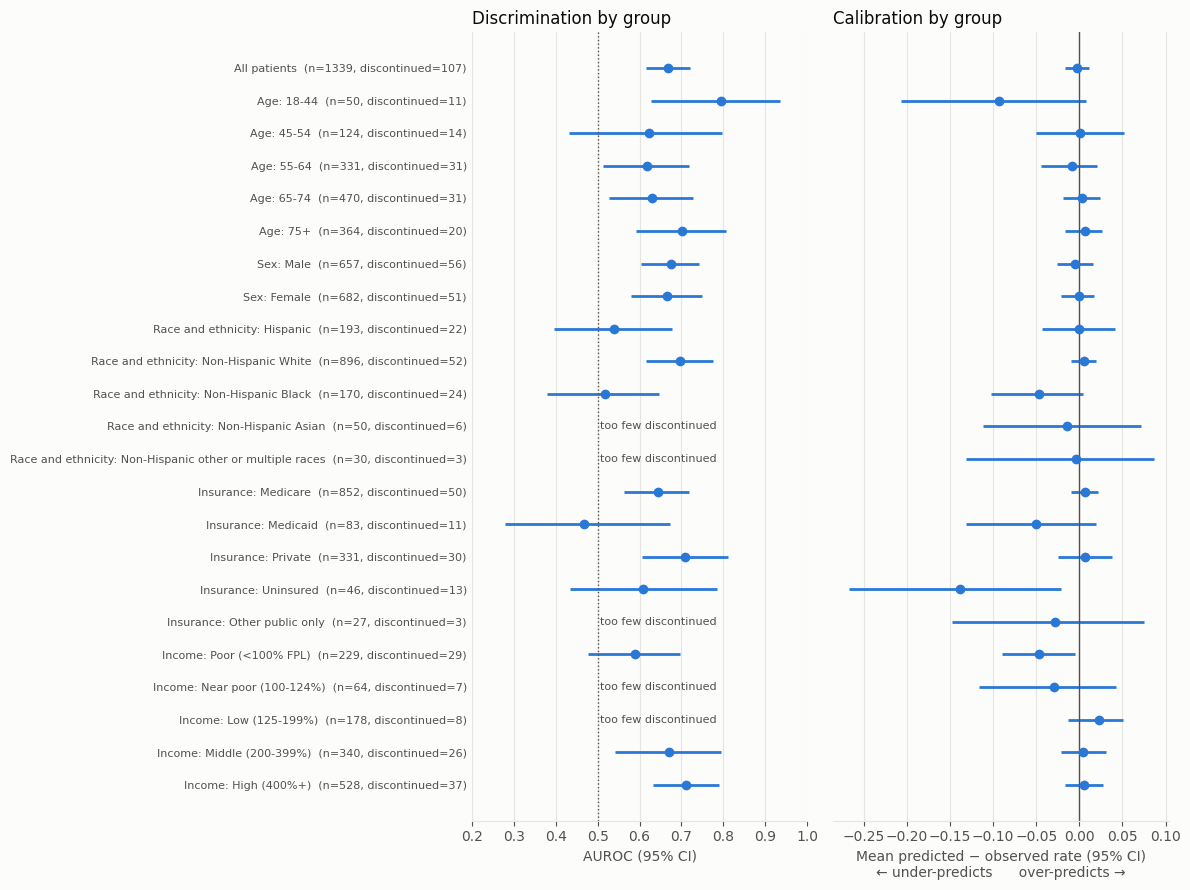

In [17]:
# Two panels, one measure each: AUROC (with CI) and calibration gap (with CI).
plot = subgroup_metrics.iloc[::-1].reset_index(drop=True)
labels = [g if s == "All" else f"{s}: {g}" for s, g in zip(plot["subgroup"], plot["group"])]
y = np.arange(len(plot))
fig, axes = plt.subplots(1, 2, figsize=(12, 9), sharey=True)

ax = axes[0]
ok = plot["auroc"].notna()
ax.errorbar(plot.loc[ok, "auroc"], y[ok],
            xerr=[plot.loc[ok, "auroc"] - plot.loc[ok, "auroc_ci_low"],
                  plot.loc[ok, "auroc_ci_high"] - plot.loc[ok, "auroc"]],
            fmt="o", color=SERIES, ecolor=SERIES, elinewidth=2, markersize=6, capsize=0)
for yi in y[~ok]:
    ax.text(0.505, yi, "too few discontinued", va="center", fontsize=8, color=INK_2)
ax.axvline(0.5, color=INK_2, linewidth=1, linestyle=":")
ax.set_xlim(0.2, 1.0)
ax.set_xlabel("AUROC (95% CI)")
ax.set_title("Discrimination by group", loc="left", fontsize=12)

ax = axes[1]
ax.errorbar(plot["calibration_gap"], y,
            xerr=[plot["calibration_gap"] - plot["calibration_gap_ci_low"],
                  plot["calibration_gap_ci_high"] - plot["calibration_gap"]],
            fmt="o", color=SERIES, ecolor=SERIES, elinewidth=2, markersize=6, capsize=0)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_xlabel("Mean predicted − observed rate (95% CI)\n← under-predicts      over-predicts →")
ax.set_title("Calibration by group", loc="left", fontsize=12)

axes[0].set_yticks(y)
axes[0].set_yticklabels([f"{l}  (n={n}, discontinued={e})" for l, n, e in zip(labels, plot["n"], plot["n_discontinued"])],
                        fontsize=8)
for a in axes:
    a.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "subgroup_metrics.png", dpi=200)
plt.show()

**Findings so far**:

**1. Overall the model is well calibrated, with moderate discrimination.**
Predicted 7.7% vs actual 8.0% discontinued (gap −0.3 points, 95% CI −1.7 to +1.1); AUROC 0.67 (0.62–0.72). The High tier holds 42% of all discontinued patients.

**2. Under-prediction is concentrated in groups with high discontinuation rates.**
- **Uninsured** (n = 46): predicted 14.4% vs actual 28.3%, gap −13.9 points (CI −26.8 to −2.1).
- **Poor, <100% FPL** (n = 229): predicted 8.0% vs actual 12.7%, gap −4.6 points (CI −9.0 to −0.5).
- Same direction, but the CI includes 0: age 18–44 (−9.3), Medicaid (−5.0), Non-Hispanic Black (−4.7).
- Low-rate groups (Non-Hispanic White, Medicare, high income) are slightly over-predicted (about +0.6 points). No group is clearly over-predicted.
- Likely reason: shallow, regularized trees pull predictions toward the overall average, so small groups with high rates are scored too low. These are the patients outreach should not miss.

**3. Within some groups the model barely ranks patients better than chance.**
AUROC is 0.54 for Hispanic (0.40–0.68), 0.52 for Non-Hispanic Black (0.38–0.65), and 0.47 for Medicaid (0.28–0.67); all CIs include 0.5, and in these groups the Brier score is no better than predicting the group's own rate. By contrast: Non-Hispanic White 0.70, Private 0.71, high income 0.71. Possible reasons: fewer training examples, and barriers in these groups (cost, access) that our features capture poorly.

**4. Age 18–44 ranks best but is under-predicted.**
AUROC 0.79 (0.63–0.93), the highest of any group, yet predicted risk is 9.3 points below actual: the model orders young patients well but scores them too low.

**5. High-tier coverage is uneven.**
Share of discontinued patients in the High tier: 73% for age 18–44 and 67% for Private, but 28% for Medicare and 27% for Medicaid. Tier-based outreach would miss most discontinued Medicare and Medicaid patients. This depends on the High-tier cut-off (placeholder 0.10, Section 9).

**6. Insufficient evidence for small groups.**
Non-Hispanic Asian (6 discontinued), other or multiple races (3), other public insurance only (3), near poor (7), and low income (8): AUROC is not reported and calibration CIs are wide (Asian: −11.2 to +7.1 points). No visible gap here is **not** evidence of fairness.

**Caveats for the report**
- Groups overlap: age and Medicare, and Medicaid and low income, describe largely the same people, so they are not independent findings.
- With 22 groups, about one CI could exclude 0 by chance. The uninsured result is large enough to stand; the poor-income result is closer to the line.
- The label is "no observed statin purchase". If some groups' purchases are recorded less completely in MEPS (free samples, mail order, cash pharmacies), part of a gap may come from the label, not the model.

## 9. Open Decisions Before the Final Run

| Decision | Owner | Current placeholder |
|---|---|---|
| Risk tier thresholds | Modeling lead / team | High ≥ 0.10, Low < 0.05 |
| `rag_driver` mapping in `driver_dictionary.csv` | Maria | Proposed in Section 3 |
| `patient_drivers.csv` columns: KAN-90 vs RAG template (`patient_id`, `risk`, `top_driver_k`, `prior_heart_or_stroke`) | Maria | KAN-90 columns plus label columns |
| `prior_heart_or_stroke` definition and source | Joseph | Not included |
| AUROC minimum discontinued patients per group | Team | 10 |
| Final model and artifacts after the Nov 16 freeze | Chris | Pre-freeze artifacts |